In [105]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import skimage as ski

In [ ]:
def find_color(rgb_img):
    img_hsv = cv.cvtColor(rgb_img, cv.COLOR_RGB2HSV)

    candidate_mask = (img_hsv[:, :, 1] >= 50) & (img_hsv[:, :, 2] >= 80)
    img_hsv = img_hsv.copy()
    img_hsv[~candidate_mask] = 0

    color_ranges = {
        "red": [
            ((0, 70, 50), (5, 255, 255)),
            ((175, 70, 50), (180, 255, 255)),
        ],
        "green": [
            ((35, 50, 50), (85, 255, 255)),
        ],
        "yellow": [
            ((20, 100, 100), (30, 255, 255)),
        ],
    }

    pixel_counts: dict[str, int] = {}

    for color, ranges in color_ranges.items():
        color_mask = np.zeros(img_hsv.shape[:2], dtype=np.uint8)

        for lower, upper in ranges:
            range_mask = cv.inRange(
                img_hsv,
                np.array(lower, dtype=np.uint8),
                np.array(upper, dtype=np.uint8),
            )
            color_mask = cv.bitwise_or(color_mask, range_mask)

        pixel_counts[color] = cv.countNonZero(color_mask)

    return max(pixel_counts, key=lambda color: pixel_counts[color])
        



In [119]:
from pathlib import Path

data_path = Path("data")

result_path = Path("/Users/asya/Downloads/hw1/result")
result_path.mkdir(parents=True, exist_ok=True)


for img_path in data_path.iterdir():
    if img_path.suffix.lower() not in {".png", ".jpg"}:
        continue

    img = cv.imread(str(img_path))

    if img is None:
        continue

    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    file_name = img_path.stem

    result = find_color(img_rgb)
    output_path = result_path / f"{result}.txt"
    with output_path.open("a", encoding="utf-8") as file:
        file.write(file_name + "\n")
    print(file_name, result)

016 green
002 green
017 red
003 red
029 red
015 green
001 green
014 yellow
028 red
010 red
004 yellow
038 green
039 red
005 green
011 red
007 red
013 green
012 green
006 red
049 red
061 green
075 red
074 red
060 yellow
048 green
062 green
063 green
073 yellow
067 green
066 red
072 green
058 yellow
070 yellow
064 yellow
059 red
071 green
065 red
068 yellow
040 green
054 green
055 yellow
041 yellow
069 red
057 red
043 green
042 red
056 green
052 green
046 red
047 green
053 green
045 red
051 red
050 green
044 yellow
023 red
037 yellow
036 red
022 green
008 red
034 red
020 red
021 green
035 green
009 green
031 green
025 yellow
019 yellow
018 yellow
024 yellow
030 red
026 red
032 yellow
033 yellow
027 red


In [84]:
def find_green(hsv_img, rgb_img):
    lower_green = np.array([35, 50, 50])
    upper_green = np.array([85, 255, 255])

    mask = cv.inRange(hsv_img, lower_green, upper_green)
    result = cv.bitwise_and(rgb_img, rgb_img, mask=mask)
    return mask, result

In [69]:
def find_yellow(hsv_img, rgb_img):
    lower_yellow = np.array([20, 100, 100])
    upper_yellow = np.array([30, 255, 255])

    mask = cv.inRange(hsv_img, lower_yellow, upper_yellow)
    result = cv.bitwise_and(rgb_img, rgb_img, mask=mask)
    return mask, result

In [70]:
def find_red(hsv_img, rgb_img):
    lower_red1 = np.array([0, 70, 50])
    upper_red1 = np.array([5, 255, 255])  
    mask1 = cv.inRange(hsv_img, lower_red1, upper_red1)
 

    lower_red2 = np.array([175, 70, 50])
    upper_red2 = np.array([180, 255, 255])
    mask2 = cv.inRange(hsv_img, lower_red2, upper_red2)

    full_mask = cv.bitwise_or(mask1, mask2)

    result = cv.bitwise_and(rgb_img, rgb_img, mask=full_mask)
    return full_mask, result


red pixels: 817
green pixels: 16
yellow pixels: 1


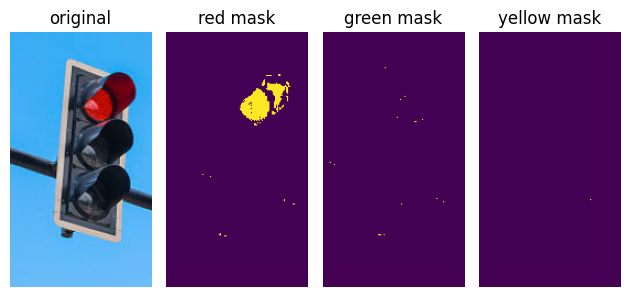

In [118]:
img_path = data_path / "065.png"
img = cv.imread(str(img_path))

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)

red_mask, red_result = find_red(img_hsv, img_rgb)
green_mask, green_result = find_green(img_hsv, img_rgb)
yellow_mask, yellow_result = find_yellow(img_hsv, img_rgb)

print("red pixels:", cv.countNonZero(red_mask))
print("green pixels:", cv.countNonZero(green_mask))
print("yellow pixels:", cv.countNonZero(yellow_mask))

fig, axes = plt.subplots(1, 4)
axes[0].imshow(img_rgb)
axes[0].set_title("original")
axes[1].imshow(red_mask)
axes[1].set_title("red mask")
axes[2].imshow(green_mask)
axes[2].set_title("green mask")
axes[3].imshow(yellow_mask)
axes[3].set_title("yellow mask")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()
